## Data Leakage test 

### CV Test vs. Holdout Validation Comparison

I0000 00:00:1794846551.204583 2817197 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794846551.225454 2817197 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794846551.716020 2817197 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1794846551.862860 2817197 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries men

=== CV Test vs Holdout Val (10-seed mean ± SD) ===
                                 CV Test (10-seed mean ± SD) Holdout Val (10-seed mean ± SD) Paired t-test p
Task             Metric                                                                                     
Classification   Accuracy                      0.857 ± 0.028                   0.852 ± 0.078           0.844
                 F1-macro                      0.848 ± 0.042                   0.815 ± 0.096           0.354
Regression (E2E) R²                            0.713 ± 0.036                   0.678 ± 0.095           0.329
                 MAE (log CFU/g)               0.433 ± 0.039                   0.465 ± 0.054           0.139

* CV Test ≈ Holdout Val → 파이프라인 leakage 없음을 지지


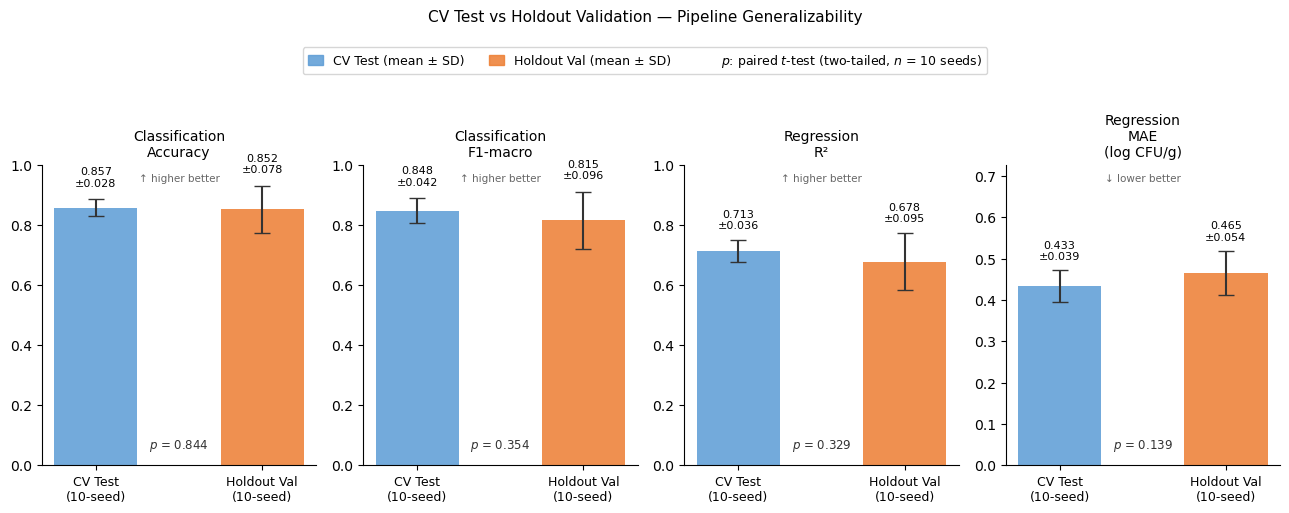

Saved: output/val_figures/val_cv_comparison.png


In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import accuracy_score, f1_score, r2_score, mean_absolute_error
from scipy import stats

import os

# Repository-relative paths. Run this notebook from the repository root.
PKL_DIR = "output/pkl"
VAL_DIR = "output/val_figures"
os.makedirs(VAL_DIR, exist_ok=True)

# ── Load ───────────────────────────────────────────────────────────
class _LSTMStub: pass
class _SafeUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if name == 'LSTMRegressor': return _LSTMStub
        return super().find_class(module, name)

with open(f"{PKL_DIR}/classification_results.pkl", 'rb') as f:
    clf_res = pickle.load(f)
with open(f"{PKL_DIR}/regression_results.pkl", 'rb') as f:
    reg_res = _SafeUnpickler(f).load()
with open(f"{PKL_DIR}/labeled_splits.pkl", 'rb') as f:
    _ls = pickle.load(f)

splits  = _ls['labeled_splits']
tpc_col = _ls['tpc_col']
SEEDS   = list(clf_res['cond1']['RandomForest'].keys())

# ── CV Test stats (per-seed 보존) ─────────────────────────────────
cv_accs = [clf_res['cond1']['RandomForest'][s]['test_acc'] for s in SEEDS]
cv_f1s  = [clf_res['cond1']['RandomForest'][s]['test_f1']  for s in SEEDS]
cv_r2s  = [reg_res['cond1']['RandomForest'][s]['test_r2']  for s in SEEDS]
cv_maes = [reg_res['cond1']['RandomForest'][s]['test_mae'] for s in SEEDS]

cv_clf_acc,     cv_clf_acc_std = np.mean(cv_accs), np.std(cv_accs)
cv_clf_f1,      cv_clf_f1_std  = np.mean(cv_f1s),  np.std(cv_f1s)
cv_reg_r2,      cv_reg_r2_std  = np.mean(cv_r2s),  np.std(cv_r2s)
cv_reg_mae,     cv_reg_mae_std = np.mean(cv_maes), np.std(cv_maes)

# ── Validation stats — 10-seed 직접 계산 ─────────────────────────
val_accs, val_f1s, val_r2s, val_maes = [], [], [], []

for seed in SEEDS:
    val_s = splits[seed]['val']

    clf_m  = clf_res['cond1']['RandomForest'][seed]['best_model']
    clf_f  = clf_res['cond1']['RandomForest'][seed]['features']
    y_val  = val_s['Label'].values
    y_pred = clf_m.predict(val_s[clf_f].values)
    val_accs.append(accuracy_score(y_val, y_pred))
    val_f1s.append(f1_score(y_val, y_pred, average='macro', zero_division=0))

    reg_m     = reg_res['cond1']['RandomForest'][seed]['best_model']
    reg_f     = reg_res['cond1']['RandomForest'][seed]['features']
    fm_mask   = pd.Series(y_pred).isin([0, 2]).values
    val_reg_s = val_s[fm_mask]
    y_pred_r  = reg_m.predict(val_reg_s[reg_f].values)
    y_true_r  = val_reg_s[tpc_col].values
    val_r2s.append(r2_score(y_true_r, y_pred_r))
    val_maes.append(mean_absolute_error(y_true_r, y_pred_r))

val_clf_acc, val_clf_acc_std = np.mean(val_accs), np.std(val_accs)
val_clf_f1,  val_clf_f1_std  = np.mean(val_f1s),  np.std(val_f1s)
val_reg_r2,  val_reg_r2_std  = np.mean(val_r2s),  np.std(val_r2s)
val_reg_mae, val_reg_mae_std = np.mean(val_maes), np.std(val_maes)

# ── Paired t-test ─────────────────────────────────────────────────
def fmt_p(p):
    if p < 0.001:
        return r'$p$ < 0.001'
    else:
        return rf'$p$ = {p:.3f}'

_, p_acc = stats.ttest_rel(cv_accs, val_accs)
_, p_f1  = stats.ttest_rel(cv_f1s,  val_f1s)
_, p_r2  = stats.ttest_rel(cv_r2s,  val_r2s)
_, p_mae = stats.ttest_rel(cv_maes, val_maes)

# ── 비교 테이블 ────────────────────────────────────────────────────
n = len(SEEDS)
rows = [
    {'Task': 'Classification',   'Metric': 'Accuracy',
     f'CV Test ({n}-seed mean ± SD)':     f"{cv_clf_acc:.3f} ± {cv_clf_acc_std:.3f}",
     f'Holdout Val ({n}-seed mean ± SD)': f"{val_clf_acc:.3f} ± {val_clf_acc_std:.3f}",
     'Paired t-test p': f"{p_acc:.3f}"},
    {'Task': 'Classification',   'Metric': 'F1-macro',
     f'CV Test ({n}-seed mean ± SD)':     f"{cv_clf_f1:.3f} ± {cv_clf_f1_std:.3f}",
     f'Holdout Val ({n}-seed mean ± SD)': f"{val_clf_f1:.3f} ± {val_clf_f1_std:.3f}",
     'Paired t-test p': f"{p_f1:.3f}"},
    {'Task': 'Regression (E2E)', 'Metric': 'R²',
     f'CV Test ({n}-seed mean ± SD)':     f"{cv_reg_r2:.3f} ± {cv_reg_r2_std:.3f}",
     f'Holdout Val ({n}-seed mean ± SD)': f"{val_reg_r2:.3f} ± {val_reg_r2_std:.3f}",
     'Paired t-test p': f"{p_r2:.3f}"},
    {'Task': 'Regression (E2E)', 'Metric': 'MAE (log CFU/g)',
     f'CV Test ({n}-seed mean ± SD)':     f"{cv_reg_mae:.3f} ± {cv_reg_mae_std:.3f}",
     f'Holdout Val ({n}-seed mean ± SD)': f"{val_reg_mae:.3f} ± {val_reg_mae_std:.3f}",
     'Paired t-test p': f"{p_mae:.3f}"},
]
cmp_df = pd.DataFrame(rows).set_index(['Task', 'Metric'])
print("=== CV Test vs Holdout Val (10-seed mean ± SD) ===")
print(cmp_df.to_string())
print()
print("* CV Test ≈ Holdout Val → 파이프라인 leakage 없음을 지지")

# ── Figure ────────────────────────────────────────────────────────
C_CV  = '#5B9BD5'
C_VAL = '#ED7D31'

metrics_info = [
    ('Classification', 'Accuracy',         cv_clf_acc, cv_clf_acc_std, val_clf_acc, val_clf_acc_std, '↑ higher better', p_acc, 1.0),
    ('Classification', 'F1-macro',          cv_clf_f1,  cv_clf_f1_std,  val_clf_f1,  val_clf_f1_std,  '↑ higher better', p_f1,  1.0),
    ('Regression',     'R²',               cv_reg_r2,  cv_reg_r2_std,  val_reg_r2,  val_reg_r2_std,  '↑ higher better', p_r2,  1.0),
    ('Regression',     'MAE\n(log CFU/g)', cv_reg_mae, cv_reg_mae_std, val_reg_mae, val_reg_mae_std, '↓ lower better',  p_mae, None),
]

fig, axes = plt.subplots(1, 4, figsize=(13, 4.5))

for ax, (task, metric, cv_m, cv_s, val_m, val_s, direction, p_val, y_max) in zip(axes, metrics_info):
    ax.bar([0], [cv_m],  width=0.5, color=C_CV,  alpha=0.85)
    ax.bar([1], [val_m], width=0.5, color=C_VAL, alpha=0.85)
    ax.errorbar(0, cv_m,  yerr=cv_s,  fmt='none', color='#333333', capsize=6, lw=1.5)
    ax.errorbar(1, val_m, yerr=val_s, fmt='none', color='#333333', capsize=6, lw=1.5)

    top = max(cv_m + cv_s, val_m + val_s)
    pad = top * 0.04
    ax.text(0, cv_m  + cv_s  + pad, f"{cv_m:.3f}\n±{cv_s:.3f}",   ha='center', va='bottom', fontsize=8)
    ax.text(1, val_m + val_s + pad, f"{val_m:.3f}\n±{val_s:.3f}", ha='center', va='bottom', fontsize=8)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['CV Test\n(10-seed)', 'Holdout Val\n(10-seed)'], fontsize=9)
    ax.set_title(f"{task}\n{metric}", fontsize=10)
    ax.set_ylim(0, y_max if y_max is not None else top * 1.40)
    ax.text(0.5, 0.97, direction, transform=ax.transAxes,
            ha='center', va='top', fontsize=7.5, color='#666666')

    # p-value annotation (이탤릭체, 각 subplot 하단)
    ax.text(0.5, 0.04, fmt_p(p_val), transform=ax.transAxes,
            ha='center', va='bottom', fontsize=8.5, color='#333333')

    ax.spines[['top', 'right']].set_visible(False)

# legend: 바 색상 + paired t-test 설명
handles = [
    Patch(color=C_CV,  alpha=0.85, label='CV Test (mean ± SD)'),
    Patch(color=C_VAL, alpha=0.85, label='Holdout Val (mean ± SD)'),
    Patch(color='none', label=r'$p$: paired $t$-test (two-tailed, $n$ = 10 seeds)'),
]
fig.legend(handles=handles, loc='upper center', ncol=3,
           fontsize=9, bbox_to_anchor=(0.5, 1.06),
           handlelength=1.2, handleheight=0.8)
fig.suptitle("CV Test vs Holdout Validation — Pipeline Generalizability",
             fontsize=11, y=1.13)
plt.tight_layout()
fig.savefig(f"{VAL_DIR}/val_cv_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {VAL_DIR}/val_cv_comparison.png")

## Permutation test

## Permutation Test — Logical Distinction Between the Two Tests

This study performs two label permutation tests (Ojala & Garriga, 2010), each addressing a distinct question.

---

### Test 1: Standard permutation (fixed features)

**What it verifies**: "Model performance is not attributable to chance (random noise)"

Features are fixed to the 10 genera of the main seed-42 model (fold-change Top10 of the seed-42 training set, Table S2), and the same 10 genera are used for classification and regression. Only the labels are randomly shuffled, and the same 5-fold CV is repeated 1,000 times.
If the observed model performance substantially exceeds the null distribution, the feature–label relationship is statistically significant.

> ⚠️ Limitation: This test demonstrates only that a relationship exists; it does not directly verify whether test-set information leaked into the feature selection process.

---

### Test 2: Full-pipeline permutation (feature re-selection)

**What it verifies**: "The feature selection step itself does not introduce data leakage"

In every fold of every permutation, 10 genera are re-selected from the training part of the fold with a **label-based stage-mean FC** (`select_fc_topn()`: the largest difference between the stage means of CLR abundance, computed with the permuted labels). For regression, the permuted TPC values are relabelled with the seed-42 Optuna thresholds (same rule as `label_by_tpc()` in `2. labeling.ipynb`), and the Early and Intermediate means are compared.

Why not the main-pipeline FC: `fold_change_top10()` in `3. screening.ipynb` ranks genera by the max − min of the **storage-day** means of CLR and does not use the labels, so permuting the labels would not change its selection. The label-based stage-mean FC is therefore used in this test.

The critical comparison is **whether the null distributions of the two tests are nearly identical**:

- Near-identical null distributions → feature selection does not inflate null performance → no leakage in the feature selection process
- Substantially different null distributions → feature selection is introducing leakage

---

### Procedure summary

| | Test 1 (Standard) | Test 2 (Full-pipeline) |
|---|---|---|
| Feature selection | Fixed: seed-42 FC Top10 (Table S2), same 10 genera for classification and regression | Re-selected per fold × per permutation with the label-based stage-mean FC |
| What is tested | Does performance exceed chance? | Does feature selection introduce leakage? |
| p-value criterion | p < 0.05 | Comparison of null distributions with Test 1 |

Both tests share the same sequence of 1,000 permutations (rng seed = 42), enabling direct comparison of their null distributions.

Data: seed-42 training + test sets (243 samples; regression uses the 207 Early and Intermediate samples). Models: the seed-42 classification and regression RF models of the main pipeline (same hyperparameters, refitted in each fold).

[Test 1 Fixed]  Acc=0.831  F1=0.801  R²=0.653  MAE=0.437
[Test 2 FP   ]  Acc=0.835   F1=0.808   R²=0.628  MAE=0.452
[100/1000] Fix: acc=0.469 r2=-0.089 | FP: acc=0.465 r2=-0.149
[200/1000] Fix: acc=0.527 r2=-0.063 | FP: acc=0.539 r2=-0.068
[300/1000] Fix: acc=0.503 r2=-0.139 | FP: acc=0.507 r2=-0.101
[400/1000] Fix: acc=0.470 r2=-0.102 | FP: acc=0.457 r2=-0.084
[500/1000] Fix: acc=0.465 r2=-0.110 | FP: acc=0.461 r2=-0.048
[600/1000] Fix: acc=0.515 r2=-0.089 | FP: acc=0.457 r2=-0.080
[700/1000] Fix: acc=0.485 r2=-0.112 | FP: acc=0.494 r2=-0.140
[800/1000] Fix: acc=0.486 r2=-0.074 | FP: acc=0.515 r2=-0.073
[900/1000] Fix: acc=0.485 r2=-0.052 | FP: acc=0.502 r2=-0.045
[1000/1000] Fix: acc=0.461 r2=-0.035 | FP: acc=0.457 r2=-0.028


/tmp/ipykernel_2817197/2851060065.py:198: UserWarning: Glyph 44160 (\N{HANGUL SYLLABLE GEOM}) missing from font(s) DejaVu Sans.
  fig1.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:198: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  fig1.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:198: UserWarning: Glyph 47785 (\N{HANGUL SYLLABLE MOG}) missing from font(s) DejaVu Sans.
  fig1.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:198: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  fig1.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:198: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig1.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:198: UserWarning: Glyph 45733 (\N{HANGUL SYLLABLE NEUNG}) missing from font(s) DejaVu Sans.
  fig1.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:198: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing

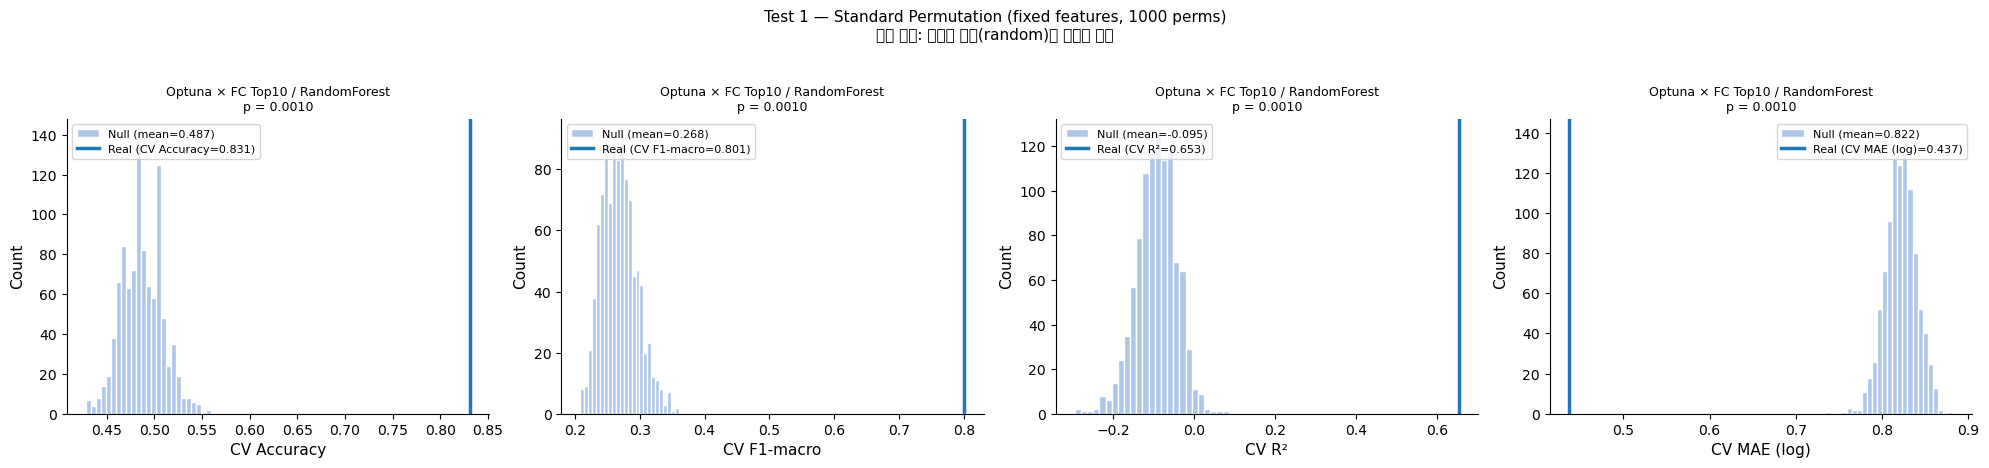

Saved: val_perm_test1_fixed.png


/tmp/ipykernel_2817197/2851060065.py:228: UserWarning: Glyph 44160 (\N{HANGUL SYLLABLE GEOM}) missing from font(s) DejaVu Sans.
  fig2.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:228: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  fig2.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:228: UserWarning: Glyph 47785 (\N{HANGUL SYLLABLE MOG}) missing from font(s) DejaVu Sans.
  fig2.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:228: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  fig2.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:228: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  fig2.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:228: UserWarning: Glyph 52404 (\N{HANGUL SYLLABLE CE}) missing from font(s) DejaVu Sans.
  fig2.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:228: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from

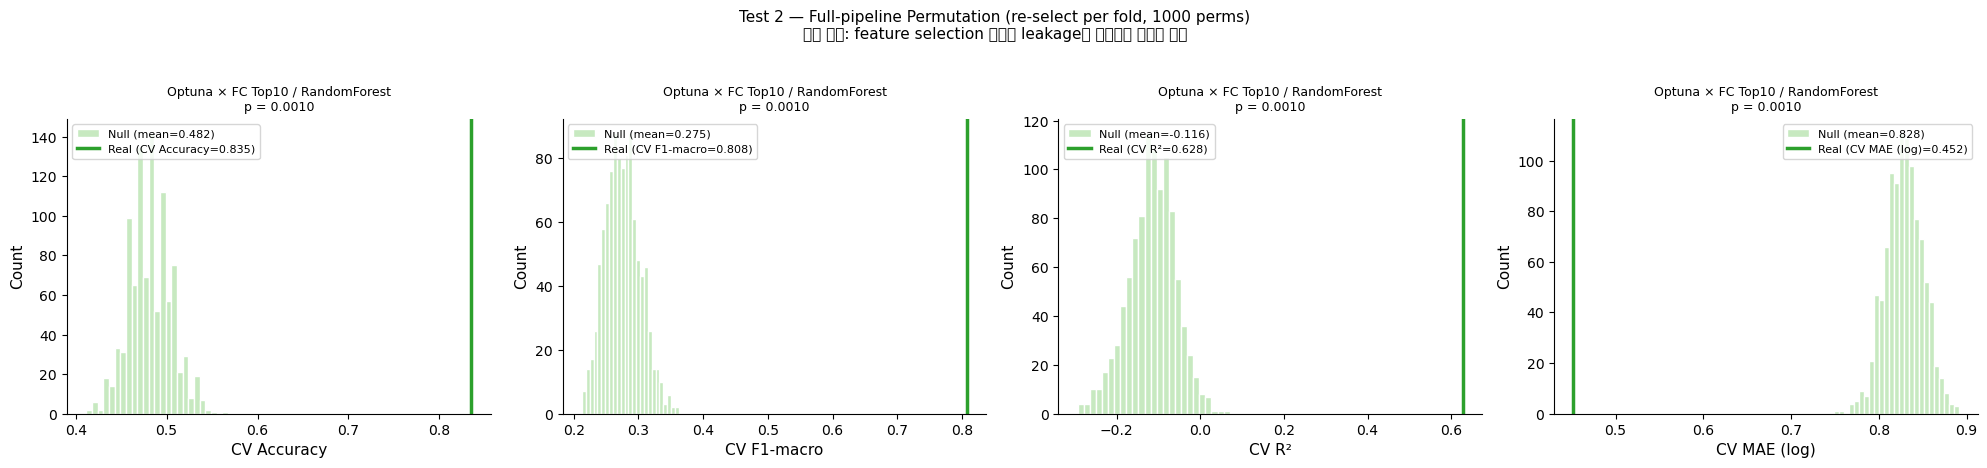

Saved: val_perm_test2_fullpipeline.png


/tmp/ipykernel_2817197/2851060065.py:262: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  fig3.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:262: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  fig3.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:262: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  fig3.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:262: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  fig3.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:262: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig3.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:262: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  fig3.tight_layout()
/tmp/ipykernel_2817197/2851060065.py:262: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font

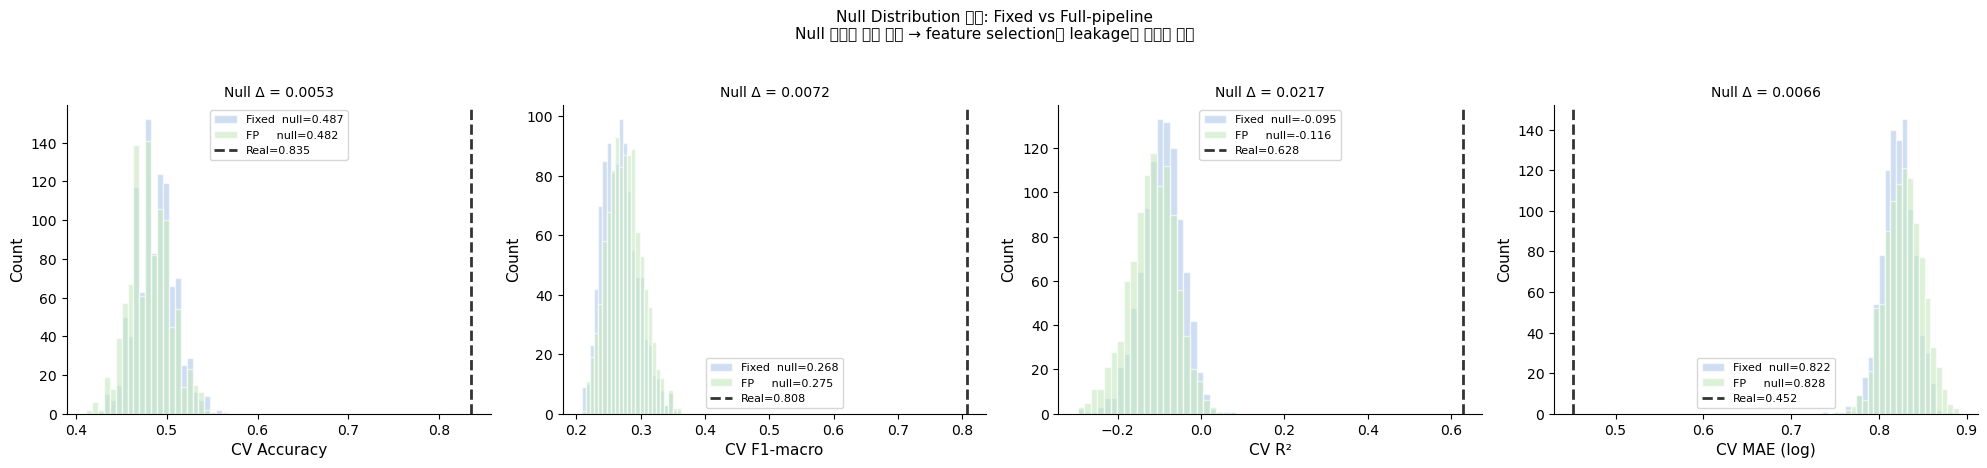

Saved: val_perm_null_comparison.png

=== Permutation Test Summary ===
지표             Fix Real   Fix Null    Fix p |  FP Real  FP Null     FP p |   Null Δ
Accuracy          0.831      0.487   0.0010 |    0.835    0.482   0.0010 |   0.0053
F1-macro          0.801      0.268   0.0010 |    0.808    0.275   0.0010 |   0.0072
R²                0.653     -0.095   0.0010 |    0.628   -0.116   0.0010 |   0.0217
MAE               0.437      0.822   0.0010 |    0.452    0.828   0.0010 |   0.0066

Saved: output/pkl/permutation_results.pkl


In [2]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, r2_score
from sklearn.model_selection import StratifiedKFold, KFold

import os

# Repository-relative paths. Run this notebook from the repository root.
PKL_DIR    = "output/pkl"
VAL_DIR    = "output/val_figures"
LABEL_SEED = 42
N_PERM     = 1000
K_FOLDS    = 5
N_TOP      = 10

# seed-42 classification model (same hyperparameters as the main seed-42 model); best_model_per_pipeline.pkl held the last SHAP-loop seed (47)
with open(f"{PKL_DIR}/best_model_pipeline.pkl", 'rb') as f:
    clf_pipe = pickle.load(f)
with open(f"{PKL_DIR}/best_reg_pipeline.pkl", 'rb') as f:
    reg_pipe = pickle.load(f)
with open(f"{PKL_DIR}/labeled_splits.pkl", 'rb') as f:
    d = pickle.load(f)
with open(f"{PKL_DIR}/screening_results.pkl", 'rb') as f:
    screen = pickle.load(f)
# seed-42 Optuna thresholds (log CFU/g), needed to relabel the permuted TPC in regression Test 2
with open(f"{PKL_DIR}/threshold_log.pkl", 'rb') as f:
    _thr = pickle.load(f)[LABEL_SEED]
THR_LOW, THR_HIGH = _thr['tpc_thr_low'], _thr['tpc_thr_high']

assert clf_pipe['seed'] == LABEL_SEED and reg_pipe['seed'] == LABEL_SEED   # both models must be the seed-42 models
clf_model     = clf_pipe['model']
reg_model     = reg_pipe['model']
tpc_col       = reg_pipe['tpc_col']
all_feat_cols = screen['feature_cols']

sp     = d['labeled_splits'][LABEL_SEED]
df_all = pd.concat([sp['train'], sp['test']], axis=0).reset_index(drop=True)
df_fm  = df_all[df_all['Label'] != 1].reset_index(drop=True)

X_clf_full   = df_all[all_feat_cols].values
y_clf        = df_all['Label'].values
X_reg_full   = df_fm[all_feat_cols].values
y_reg        = df_fm[tpc_col].values
y_reg_labels = df_fm['Label'].values

# label_by_tpc() rule of 2. labeling.ipynb (Early=0, Late=1, Intermediate=2) with the seed-42 Optuna thresholds, for relabelling permuted TPC
def tpc_to_label(tpc):
    return np.where(tpc < THR_LOW, 0, np.where(tpc >= THR_HIGH, 1, 2))
assert np.array_equal(tpc_to_label(y_reg), y_reg_labels)   # the rule reproduces the stored labels

clf_splits = list(StratifiedKFold(n_splits=K_FOLDS, shuffle=True,
                                  random_state=42).split(X_clf_full, y_clf))
reg_splits = list(KFold(n_splits=K_FOLDS, shuffle=True,
                        random_state=42).split(X_reg_full))

clf_label = f"{clf_pipe['cond_label']} / {clf_pipe['model_name']}"
reg_label = f"{reg_pipe['cond_label']} / {reg_pipe['model_name']}"

# ── Helper: label-based stage-mean FC Top-N (Test 2 re-selection) ──────────
# Max difference between stage (label) means of CLR. The main-pipeline FC (fold_change_top10, 3. screening.ipynb)
# uses storage-day means and no labels, so permuting the labels would not change its selection.
def select_fc_topn(X_tr, y_tr, n_top=N_TOP):
    classes = np.unique(y_tr)
    if len(classes) < 2:
        return np.arange(n_top)
    means    = [X_tr[y_tr == c].mean(axis=0) for c in classes]
    max_diff = np.zeros(X_tr.shape[1])
    for i in range(len(means)):
        for j in range(i + 1, len(means)):
            max_diff = np.maximum(max_diff, np.abs(means[i] - means[j]))
    return np.argsort(max_diff)[::-1][:n_top]

# ── Test 1: 고정 피처 함수 ─────────────────────────────────────────
def run_fix_clf(X_fix, y, splits):
    accs, f1s = [], []
    for tr, te in splits:
        m  = clone(clf_model).fit(X_fix[tr], y[tr])
        yp = m.predict(X_fix[te])
        accs.append(accuracy_score(y[te], yp))
        f1s.append(f1_score(y[te], yp, average='macro'))
    return np.mean(accs), np.mean(f1s)

def run_fix_reg(X_fix, y_r, splits):
    r2s, maes = [], []
    for tr, te in splits:
        m  = clone(reg_model).fit(X_fix[tr], y_r[tr])
        yp = m.predict(X_fix[te])
        r2s.append(r2_score(y_r[te], yp))
        maes.append(np.mean(np.abs(y_r[te] - yp)))
    return np.mean(r2s), np.mean(maes)

# ── Test 2: Full-pipeline 함수 ─────────────────────────────────────
def run_fp_clf(X_full, y, splits):
    accs, f1s = [], []
    for tr, te in splits:
        idx = select_fc_topn(X_full[tr], y[tr])
        m   = clone(clf_model).fit(X_full[tr][:, idx], y[tr])
        yp  = m.predict(X_full[te][:, idx])
        accs.append(accuracy_score(y[te], yp))
        f1s.append(f1_score(y[te], yp, average='macro'))
    return np.mean(accs), np.mean(f1s)

def run_fp_reg(X_full, y_r, y_labels, splits):
    r2s, maes = [], []
    for tr, te in splits:
        idx = select_fc_topn(X_full[tr], y_labels[tr])
        m   = clone(reg_model).fit(X_full[tr][:, idx], y_r[tr])
        yp  = m.predict(X_full[te][:, idx])
        r2s.append(r2_score(y_r[te], yp))
        maes.append(np.mean(np.abs(y_r[te] - yp)))
    return np.mean(r2s), np.mean(maes)

# ── Test 1 Setup: features fixed to the main seed-42 model (FC Top10 of the seed-42 training set, Table S2) ──
# same 10 genera for classification and regression; previously re-selected here with select_fc_topn() on the 243 samples
FIX_FEATS   = list(screen['cond1_optuna_fc10']['per_seed_features'][LABEL_SEED])
assert FIX_FEATS == list(clf_pipe['features']) == list(reg_pipe['features'])   # same 10 as the seed-42 models
clf_idx_fix = np.array([all_feat_cols.index(f) for f in FIX_FEATS])
reg_idx_fix = clf_idx_fix
X_clf_fix   = X_clf_full[:, clf_idx_fix]
X_reg_fix   = X_reg_full[:, reg_idx_fix]

# ── Real scores ────────────────────────────────────────────────────
real_acc_fix, real_f1_fix             = run_fix_clf(X_clf_fix, y_clf, clf_splits)
real_r2_fix,  real_mae_fix            = run_fix_reg(X_reg_fix, y_reg, reg_splits)
real_acc_fp,  real_f1_fp              = run_fp_clf(X_clf_full, y_clf, clf_splits)
real_r2_fp,   real_mae_fp            = run_fp_reg(X_reg_full, y_reg, y_reg_labels, reg_splits)

print(f"[Test 1 Fixed]  Acc={real_acc_fix:.3f}  F1={real_f1_fix:.3f}  "
      f"R²={real_r2_fix:.3f}  MAE={real_mae_fix:.3f}")
print(f"[Test 2 FP   ]  Acc={real_acc_fp:.3f}   F1={real_f1_fp:.3f}   "
      f"R²={real_r2_fp:.3f}  MAE={real_mae_fp:.3f}")

# ── Permutation loop (동일 치환 시퀀스 공유) ──────────────────────
rng = np.random.default_rng(42)
perm_acc_fix, perm_f1_fix, perm_r2_fix, perm_mae_fix = [], [], [], []
perm_acc_fp,  perm_f1_fp,  perm_r2_fp,  perm_mae_fp  = [], [], [], []

for i in range(N_PERM):
    py_clf        = rng.permutation(y_clf)
    py_reg        = rng.permutation(y_reg)
    # relabel permuted TPC with the seed-42 thresholds; the old rank indexing assumed TPC-sorted rows and mislabelled py_reg
    py_reg_labels = tpc_to_label(py_reg)

    a1, f1_ = run_fix_clf(X_clf_fix, py_clf, clf_splits)
    r1, m1  = run_fix_reg(X_reg_fix, py_reg, reg_splits)
    perm_acc_fix.append(a1); perm_f1_fix.append(f1_)
    perm_r2_fix.append(r1);  perm_mae_fix.append(m1)

    a2, f2_ = run_fp_clf(X_clf_full, py_clf, clf_splits)
    r2_, m2 = run_fp_reg(X_reg_full, py_reg, py_reg_labels, reg_splits)
    perm_acc_fp.append(a2); perm_f1_fp.append(f2_)
    perm_r2_fp.append(r2_);  perm_mae_fp.append(m2)

    if (i + 1) % 100 == 0:
        print(f"[{i+1}/{N_PERM}] Fix: acc={a1:.3f} r2={r1:.3f} | "
              f"FP: acc={a2:.3f} r2={r2_:.3f}")

perm_acc_fix = np.array(perm_acc_fix); perm_f1_fix = np.array(perm_f1_fix)
perm_r2_fix  = np.array(perm_r2_fix);  perm_mae_fix = np.array(perm_mae_fix)
perm_acc_fp  = np.array(perm_acc_fp);  perm_f1_fp  = np.array(perm_f1_fp)
perm_r2_fp   = np.array(perm_r2_fp);   perm_mae_fp  = np.array(perm_mae_fp)

def pval(perm, real): return (np.sum(perm >= real) + 1) / (N_PERM + 1)

p_acc_fix = pval(perm_acc_fix, real_acc_fix); p_f1_fix = pval(perm_f1_fix, real_f1_fix)
p_r2_fix  = pval(perm_r2_fix,  real_r2_fix);  p_mae_fix = pval(-perm_mae_fix, -real_mae_fix)
p_acc_fp  = pval(perm_acc_fp,  real_acc_fp);  p_f1_fp  = pval(perm_f1_fp,  real_f1_fp)
p_r2_fp   = pval(perm_r2_fp,   real_r2_fp);   p_mae_fp  = pval(-perm_mae_fp, -real_mae_fp)

# ─────────────────────────────────────────────────────────────────
# Figure 1: Test 1 (고정 피처) — 4 metrics
# ─────────────────────────────────────────────────────────────────
fig1, axes = plt.subplots(1, 4, figsize=(20, 4.5))
tasks1 = [
    (axes[0], perm_acc_fix, real_acc_fix, p_acc_fix, 'CV Accuracy',   clf_label, True),
    (axes[1], perm_f1_fix,  real_f1_fix,  p_f1_fix,  'CV F1-macro',   clf_label, True),
    (axes[2], perm_r2_fix,  real_r2_fix,  p_r2_fix,  'CV R²',         reg_label, True),
    (axes[3], perm_mae_fix, real_mae_fix, p_mae_fix, 'CV MAE (log)',   reg_label, False),
]
for ax, pv, rv, pv_p, metric, label, higher_better in tasks1:
    ax.hist(pv, bins=25, color='#aec7e8', edgecolor='white',
            label=f'Null (mean={pv.mean():.3f})')
    ax.axvline(rv, color='#1f77b4', lw=2.5,
               label=f'Real ({metric}={rv:.3f})')
    ax.set_xlabel(metric, fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.set_title(f"{label}\np = {pv_p:.4f}", fontsize=9)
    ax.legend(fontsize=8, loc='upper left' if higher_better else 'upper right')
    ax.spines[['top', 'right']].set_visible(False)

fig1.suptitle(
    f"Test 1 — Standard Permutation (fixed features, {N_PERM} perms)\n"
    f"검증 목적: 성능이 우연(random)이 아님을 확인",
    fontsize=11, y=1.03)
fig1.tight_layout()
fig1.savefig(f"{VAL_DIR}/val_perm_test1_fixed.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: val_perm_test1_fixed.png")

# ─────────────────────────────────────────────────────────────────
# Figure 2: Test 2 (Full-pipeline) — 4 metrics
# ─────────────────────────────────────────────────────────────────
fig2, axes = plt.subplots(1, 4, figsize=(20, 4.5))
tasks2 = [
    (axes[0], perm_acc_fp, real_acc_fp, p_acc_fp, 'CV Accuracy', clf_label, True),
    (axes[1], perm_f1_fp,  real_f1_fp,  p_f1_fp,  'CV F1-macro', clf_label, True),
    (axes[2], perm_r2_fp,  real_r2_fp,  p_r2_fp,  'CV R²',       reg_label, True),
    (axes[3], perm_mae_fp, real_mae_fp, p_mae_fp, 'CV MAE (log)', reg_label, False),
]
for ax, pv, rv, pv_p, metric, label, higher_better in tasks2:
    ax.hist(pv, bins=25, color='#c7e9c0', edgecolor='white',
            label=f'Null (mean={pv.mean():.3f})')
    ax.axvline(rv, color='#2ca02c', lw=2.5,
               label=f'Real ({metric}={rv:.3f})')
    ax.set_xlabel(metric, fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.set_title(f"{label}\np = {pv_p:.4f}", fontsize=9)
    ax.legend(fontsize=8, loc='upper left' if higher_better else 'upper right')
    ax.spines[['top', 'right']].set_visible(False)

fig2.suptitle(
    f"Test 2 — Full-pipeline Permutation (re-select per fold, {N_PERM} perms)\n"
    f"검증 목적: feature selection 자체가 leakage를 유발하지 않음을 확인",
    fontsize=11, y=1.03)
fig2.tight_layout()
fig2.savefig(f"{VAL_DIR}/val_perm_test2_fullpipeline.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: val_perm_test2_fullpipeline.png")

# ─────────────────────────────────────────────────────────────────
# Figure 3: Null distribution 비교 (동일 치환, 두 테스트 overlay)
# ─────────────────────────────────────────────────────────────────
fig3, axes = plt.subplots(1, 4, figsize=(20, 4.5))
compare = [
    (axes[0], perm_acc_fix, perm_acc_fp, real_acc_fp, 'CV Accuracy'),
    (axes[1], perm_f1_fix,  perm_f1_fp,  real_f1_fp,  'CV F1-macro'),
    (axes[2], perm_r2_fix,  perm_r2_fp,  real_r2_fp,  'CV R²'),
    (axes[3], perm_mae_fix, perm_mae_fp, real_mae_fp, 'CV MAE (log)'),
]
for ax, pv_fix, pv_fp, rv, metric in compare:
    bins = np.linspace(min(pv_fix.min(), pv_fp.min()),
                       max(pv_fix.max(), pv_fp.max()), 25)
    ax.hist(pv_fix, bins=bins, color='#aec7e8', alpha=0.6, edgecolor='white',
            label=f'Fixed  null={pv_fix.mean():.3f}')
    ax.hist(pv_fp,  bins=bins, color='#c7e9c0', alpha=0.6, edgecolor='white',
            label=f'FP     null={pv_fp.mean():.3f}')
    ax.axvline(rv, color='#333333', lw=2, linestyle='--', label=f'Real={rv:.3f}')
    ax.set_xlabel(metric, fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    delta = abs(pv_fix.mean() - pv_fp.mean())
    ax.set_title(f"Null Δ = {delta:.4f}", fontsize=10)
    ax.legend(fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)

fig3.suptitle(
    "Null Distribution 비교: Fixed vs Full-pipeline\n"
    "Null 분포가 거의 동일 → feature selection이 leakage를 만들지 않음",
    fontsize=11, y=1.03)
fig3.tight_layout()
fig3.savefig(f"{VAL_DIR}/val_perm_null_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: val_perm_null_comparison.png")

# ── 콘솔 요약 ─────────────────────────────────────────────────────
print("\n=== Permutation Test Summary ===")
print(f"{'지표':<12} {'Fix Real':>10} {'Fix Null':>10} {'Fix p':>8} | "
      f"{'FP Real':>8} {'FP Null':>8} {'FP p':>8} | {'Null Δ':>8}")
for metric, rv1, nv1, p1, rv2, nv2, p2 in [
    ('Accuracy',  real_acc_fix, perm_acc_fix.mean(), p_acc_fix,
                  real_acc_fp,  perm_acc_fp.mean(),  p_acc_fp),
    ('F1-macro',  real_f1_fix,  perm_f1_fix.mean(),  p_f1_fix,
                  real_f1_fp,   perm_f1_fp.mean(),   p_f1_fp),
    ('R²',        real_r2_fix,  perm_r2_fix.mean(),  p_r2_fix,
                  real_r2_fp,   perm_r2_fp.mean(),   p_r2_fp),
    ('MAE',       real_mae_fix, perm_mae_fix.mean(), p_mae_fix,
                  real_mae_fp,  perm_mae_fp.mean(),  p_mae_fp),
]:
    print(f"{metric:<12} {rv1:>10.3f} {nv1:>10.3f} {p1:>8.4f} | "
          f"{rv2:>8.3f} {nv2:>8.3f} {p2:>8.4f} | "
          f"{abs(nv1-nv2):>8.4f}")

# ── permutation_results.pkl 저장 ──────────────────────────────────
permutation_results = {
    'n_perm': N_PERM,
    'real': {
        'test1_acc': real_acc_fix, 'test1_f1': real_f1_fix,
        'test1_r2':  real_r2_fix,  'test1_mae': real_mae_fix,
        'test2_acc': real_acc_fp,  'test2_f1':  real_f1_fp,
        'test2_r2':  real_r2_fp,   'test2_mae': real_mae_fp,
    },
    'null_test1': {
        'acc': np.asarray(perm_acc_fix), 'f1':  np.asarray(perm_f1_fix),
        'r2':  np.asarray(perm_r2_fix),  'mae': np.asarray(perm_mae_fix),
    },
    'null_test2': {
        'acc': np.asarray(perm_acc_fp),  'f1':  np.asarray(perm_f1_fp),
        'r2':  np.asarray(perm_r2_fp),   'mae': np.asarray(perm_mae_fp),
    },
    'pval': {
        'test1_acc': p_acc_fix, 'test1_f1': p_f1_fix,
        'test1_r2':  p_r2_fix,  'test1_mae': p_mae_fix,
        'test2_acc': p_acc_fp,  'test2_f1': p_f1_fp,
        'test2_r2':  p_r2_fp,   'test2_mae': p_mae_fp,
    },
}
with open(f"{PKL_DIR}/permutation_results.pkl", 'wb') as f:
    pickle.dump(permutation_results, f)
print(f"\nSaved: {PKL_DIR}/permutation_results.pkl")


## Permutation Test — Results and Interpretation

### Test 1 (Fixed features) — "Performance is not attributable to chance"

| Metric | Real model | Null mean | p |
|---|---|---|---|
| CV Accuracy | 0.831 | 0.487 | ≤ 0.001 |
| CV F1-macro | 0.801 | 0.268 | ≤ 0.001 |
| CV R²       | 0.653 | −0.095 | ≤ 0.001 |
| CV MAE      | 0.437 | 0.822 | ≤ 0.001 |

None of the 1,000 permutations exceeded the observed performance on any of the four metrics (p ≤ 0.001).  
→ Model performance is not attributable to random noise.

---

### Test 2 (Full-pipeline) — "Feature selection itself does not introduce leakage"

| Metric | Real model | Null mean | p | Δ from Test 1 null |
|---|---|---|---|---|
| CV Accuracy | 0.835 | 0.482 | ≤ 0.001 | 0.005 |
| CV F1-macro | 0.808 | 0.275 | ≤ 0.001 | 0.007 |
| CV R²       | 0.628 | −0.116 | ≤ 0.001 | 0.022 |
| CV MAE      | 0.452 | 0.828 | ≤ 0.001 | 0.007 |

Even with the top 10 genera re-selected by the label-based stage-mean FC using permuted labels in every fold of every permutation, the null distribution remained virtually identical to that of Test 1 (Δ ≤ 0.022 across all metrics).  
→ **Directly confirms that the feature selection step itself does not introduce data leakage.**

---

### Null distribution interpretation

- **Null Accuracy ≈ 0.482–0.487**: Convergence to ~0.5 rather than the uniform 3-class expectation (0.333) is expected, as the higher proportion of Early samples means a majority-class strategy achieves above-chance accuracy → expected behavior
- **Null R² ≈ −0.095 to −0.116**: Regression on permuted labels performs worse than the mean predictor → expected behavior
- **Null MAE ≈ 0.822–0.828**: Large prediction error under randomized labels → expected behavior

---

### Key interpretation — Null distribution comparison

The difference between the two null distributions is negligible across all metrics (Δ ≤ 0.022).  
If feature selection were leaking test-set information, the full-pipeline null distribution would be **higher** — not lower — because feature selection would adapt to the permuted labels and produce some degree of artificial separation. The near-identical null distributions confirm that **feature selection improves performance only when a genuine feature–label relationship exists.**

Note: A slight reversal is observed for the F1 null (full-pipeline: 0.275 vs. fixed: 0.268). Re-selecting features using permuted labels per fold introduces noise into the feature set itself, marginally widening the null distribution — this is unrelated to leakage, and Δ = 0.007 falls within the range of sampling error.

---

> **Hyperparameter tuning is fixed based on the original labels**: A fully exhaustive pipeline would require re-running GridSearchCV at every permutation, which would demand upwards of five million model fits and is computationally infeasible.